### Model Development, Pipline Development and Model Deployment 
- In this notebook we will use already face cropped data of males and females stored in a pickle file and each image has been resized to 100 by 100.

# Section 1 Model Development

In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [3]:
# loading the already saved data
# laoding dataset stored in pickle file
df = pickle.load(open("./100_100_male_female","rb"))

In [4]:
# chekcing the first few rows
df.head()

,0,1,2,3,4,5,6,7,8,9,...,9991,9992,9993,9994,9995,9996,9997,9998,9999,gender
0,137,137,138,140,140,141,142,143,142,141,...,103,103,103,103,102,102,102,103,103,male
1,188,149,71,63,49,44,59,58,43,55,...,220,222,222,222,222,222,222,222,222,male
2,12,15,13,14,13,14,25,38,37,36,...,49,50,40,37,45,68,76,64,44,male
3,42,40,39,38,37,39,46,55,63,59,...,33,32,32,31,33,33,32,31,33,male
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,7,23,0,0,0,male


In [41]:
# splitting the data into features and target
X = df.drop("gender",axis=1)
y = df[["gender"]]

In [42]:
X.reset_index(inplace=True)
X.drop("index",axis=1,inplace=True)

In [43]:
X.head()

,0,1,2,3,4,5,6,7,8,9,...,9990,9991,9992,9993,9994,9995,9996,9997,9998,9999
0,137,137,138,140,140,141,142,143,142,141,...,103,103,103,103,103,102,102,102,103,103
1,188,149,71,63,49,44,59,58,43,55,...,220,220,222,222,222,222,222,222,222,222
2,12,15,13,14,13,14,25,38,37,36,...,55,49,50,40,37,45,68,76,64,44
3,42,40,39,38,37,39,46,55,63,59,...,34,33,32,32,31,33,33,32,31,33
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,7,23,0,0,0


### Eigen faces
- Following are the steps to convert faces into eigen faces:
- First, standardize the images using standard scaler
- After, that apply PCA and see what n_components are given the best variance
- Then, make a PCA model with those number of components nad apply on your data
- Then, after you have transformed the data into PCA componnets, reconstruct the data.
- This reconstructed data will contain the eigen faces

In [6]:
# applying standard scaler on the X to scale the images
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
pca_experiment = PCA(n_components=None, whiten=True,svd_solver="auto")
pca_experiment_data = pca_experiment.fit_transform(X_scaled)

# now getting explained variance ratio how much variance is explained by each feature
feature_variance = pca_experiment.explained_variance_ratio_

# now lets get cumulative variance how much variance is explained by 10 features ,20, 50 or 100
cumsum_variance = np.cumsum(feature_variance)

Text(0, 0.5, 'Cumulative explained variance ration')

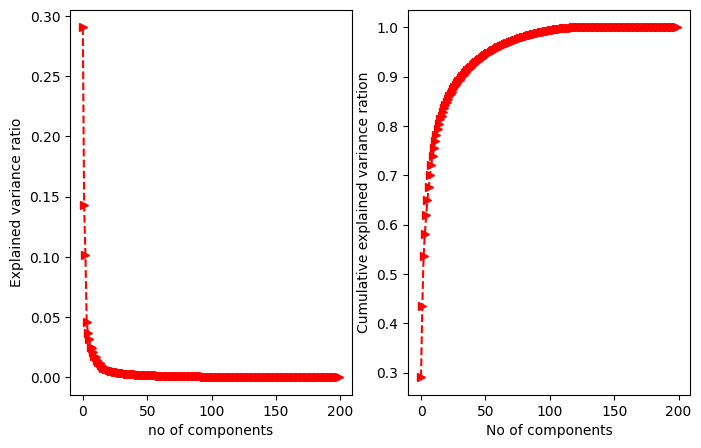

In [8]:
# now let's plot the variance grapghs individual and cumulative
plt.figure(figsize=(8,5))
plt.subplot(1,2,1)
plt.plot(feature_variance[:200],"r>--")
plt.xlabel("no of components")
plt.ylabel("Explained variance ratio")

plt.subplot(1,2,2)
plt.plot(cumsum_variance[:200],"r>--")
plt.xlabel("No of components")
plt.ylabel("Cumulative explained variance ration")

- As we can see only 50 components or features are capable o explaining nearly 90% of variance in the data and 100 componnets are capable of explaining more than 90% of variance in the data.

In [12]:
# now we will make a pca model with 100 componnets
pca_selected = PCA(n_components=100)

# now we wil transform the scaled data to containe 100 components
X_pca = pca_selected.fit_transform(X_scaled)

# eigen faces
eigen_faces = pca_selected.components_

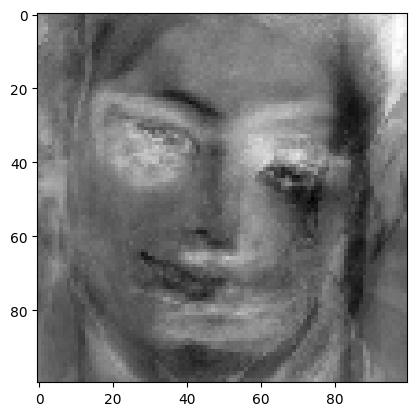

In [20]:
# visualizing an eigen face
plt.imshow(eigen_faces[10].reshape(100,100),cmap="gray")

In [22]:
# now after x_scaled has been transformed, now we will reconstruct data using inverse transform
reconstructed_data = pca_selected.inverse_transform(X_pca)

print("Shape of transformed data",X_pca.shape)
print("Shape of reconstructed data from transformed data",reconstructed_data.shape)

Shape of transformed data (200, 100)
Shape of reconstructed data from transformed data (200, 10000)


In [32]:
np.random.seed(4)
random_number = np.random.randint(0,200,10)
random_number

array([122, 174, 183, 197, 129, 104,  87,  50, 137,  58])

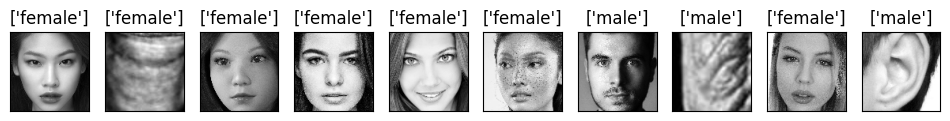

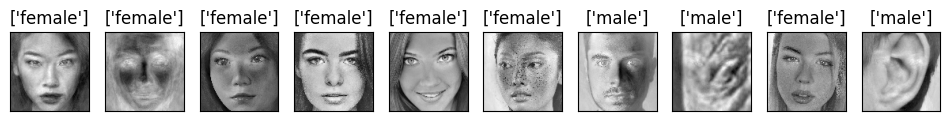

In [44]:
plt.figure(figsize=(12,10))
for i, img in enumerate(random_number):
    plt.subplot(1,10,i+1)
    plt.imshow(X.loc[img,:].values.reshape(100,100),cmap="gray")
    plt.title(y.values[img])
    plt.xticks([])
    plt.yticks([])

plt.show()
print("=" * 50)

plt.figure(figsize=(12,10))
for i, img_number in enumerate(random_number):
    plt.subplot(1,10,i+1)
    plt.imshow(reconstructed_data[img_number].reshape(100,100),cmap="gray")
    plt.title(y.values[img_number])
    plt.xticks([])
    plt.yticks([])


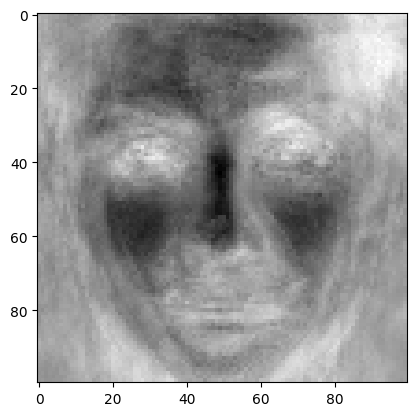

In [49]:
# now using the reconstructed data to visualize faces
# showing first 10 images of male and females
plt.imshow(reconstructed_data[174].reshape(100,100),cmap="gray")

In [50]:
# This code is from chatgpt

# # Step 2: Reshape the data - images are already flattened in the dataframe
# # Each image is represented by 10000 pixel values (100x100)
# # We can directly apply PCA on X since it's already a 2D array of size (100, 10000)

# # Step 3: Normalize the data
# # Normalize the data by subtracting the mean of each feature (pixel)
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

# # Step 4: Apply PCA
# n_components = 100  # Number of eigenfaces to extract
# pca = PCA(n_components=n_components)
# X_pca = pca.fit_transform(X_scaled)

# # Step 5: Visualize the eigenfaces
# # Eigenfaces are the principal components (the eigenvectors)
# eigenfaces = pca.components_

# # Plot the first few eigenfaces
# fig, axes = plt.subplots(5, 5, figsize=(10, 10))
# for i, ax in enumerate(axes.flat):
#     ax.imshow(eigenfaces[i].reshape(100, 100), cmap='gray')  # Reshape each eigenface to 100x100
#     ax.set_title(f'Eigenface {i+1}')
#     ax.axis('off')
# plt.tight_layout()
# plt.show()

# # Step 6: Project the original images onto the eigenfaces
# # This is the representation of each image in the eigenface space (lower-dimensional space)
# X_projected = pca.transform(X_scaled)

# # Step 7: Check the shape of projected data
# print(f"Shape of projected data: {X_projected.shape}")  # Should be (100, n_components)

# # Optional: To reconstruct an image from the eigenface space, you can inverse transform:
# X_reconstructed = pca.inverse_transform(X_projected)

# # Reconstruct an image from the first row (first image) in the dataset
# reconstructed_image = X_reconstructed[0].reshape(100, 100)

# # Plot the reconstructed image
# plt.imshow(reconstructed_image, cmap='gray')
# plt.title("Reconstructed Image")
# plt.axis('off')
# plt.show()


In [51]:
reconstructed_data.shape

(200, 10000)

# Model Development

In [52]:
X_train,X_test,y_train,y_test = train_test_split(X_pca,y,test_size=0.2,random_state=31)

In [57]:
from sklearn.svm import SVC

In [58]:
# Initialize the Support Vector Classifier (SVC)
model = SVC(probability=True)

# Train the model on the training data
model.fit(X_train, y_train)

# Calculate accuracy on the training data using score method
train_accuracy = model.score(X_train, y_train)
print(f"Training accuracy: {train_accuracy * 100:.2f}%")

# Calculate accuracy on the testing data using score method
test_accuracy = model.score(X_test, y_test)
print(f"Testing accuracy: {test_accuracy * 100:.2f}%")

Training accuracy: 97.50%
Testing accuracy: 85.00%


c:\Users\SaaD Computer\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [60]:
# saving the SVC model
pickle.dump(model,open("svc_model.pkl","wb"))
# saving the pca transformation applied model
pickle.dump(pca_selected,open("pca_model.pkl","wb"))

# standard scaler model for pipeline
pickle.dump(scaler,open("standardscaler.pkl","wb"))

# Pipeline Building

In [61]:
import cv2

In [64]:
# load the har cascade model
har_model = cv2.CascadeClassifier("haarcascade_frontalface_default.xml")

# load the svc_model
svc_model = pickle.load(open("svc_model.pkl","rb"))

# loading the pca transformation
pca_transformation_model = pickle.load(open("pca_model.pkl","rb"))

# loading the standard scaler
scaler_model = pickle.load(open("standardscaler.pkl","rb"))

In [65]:
# setting gender
gender_pre = ["female","male"]
font = cv2.FONT_HERSHEY_SIMPLEX

In [88]:
test_image = "test_images\\1 (3).png"
test_img = cv2.imread(test_image)

color = "bgr"

In [89]:
test_img.shape

(981, 736, 3)

In [90]:
def pipline(img,color="rgb"):

    # step # 1 converting a rgb or bgr image into Gray
    if color == "rgb":
        gray = cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)
    else:
        gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

    # step # 2 detecting the face using harcascade model
    face = har_model.detectMultiScale(gray, scaleFactor=1.1,minNeighbors=5)

    for x,y,w,h in face:
        cv2.rectangle(img,(x,y),(x+w,y+h),(0,255,0),2)

        roi = gray[y:y+h,x:x+w]

        # roi = roi /255

    # step 3 shrinking the image if it is large or expanding it if it is small
    if roi.shape[1] > 100:
        roi_resize = cv2.resize(roi,(100,100),cv2.INTER_AREA)

    else:
        roi_resize = cv2.resize(roi,(100,100),cv2.INTER_CUBIC)

    resized_image = roi_resize.reshape(1,10000)
    scaled_image = scaler_model.transform(resized_image)
    # flatteing the image
    #flattened_image = roi_resize.reshape(1,10000)

    #flattened_image = roi_mean.reshape(1,10000)

    # eigen image
    eigen_image = pca_transformation_model.transform(scaled_image)

    # prediction on eigen image
    prediction = svc_model.predict(eigen_image)
    #print(prediction)

    # probabilities
    # probabilities = svc_model.predict_proba(eigen_image)[prediction]

    # print("prdiction is",prediction[0])
    # if prediction[0] < 1:
    #     print("it is a female")

    # else:
    #     print("it is a male")

    
    # text = f",prob {probabilities}"
    # cv2.putText(img, text, (x,y),font,1,(0,255,0),1)

    return img,prediction
    

In [91]:
img,predicted_label = pipline(test_img,color=color)

Text(0.5, 1.0, "Predicted label is ['male']")

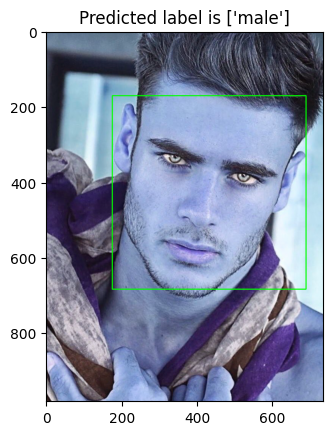

In [92]:
plt.imshow(img,cmap="gray")
plt.title(f"Predicted label is {predicted_label}")